In [2]:
import pandas as pd
import numpy as np
import ast

from sklearn.model_selection import GroupKFold, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.pipeline import Pipeline

In [3]:
df = pd.read_csv("gurgaon_properties_cleaned_v1 (2).csv")

print("Dataset shape:", df.shape)
df.head()

Dataset shape: (3803, 17)


,property_type,society,sector,price,price_per_sqft,area,areaWithType,bedRoom,bathroom,balcony,additionalRoom,floorNum,facing,agePossession,nearbyLocations,furnishDetails,features
0,flat,signature global park 4,sector 36,0.82,7585.0,1081.0,Super Built up area 1081(100.43 sq.m.)Carpet a...,3,2,2,not available,2.0,NaN,0 to 1 Year Old,"['Sector 55-56 Metro Station', 'The Leaf Mall ...",NaN,"['Lift(s)', 'Park']"
1,flat,smart world gems,sector 89,0.95,8600.0,1105.0,Carpet area: 1103 (102.47 sq.m.),2,2,2,"study room,servant room",4.0,NaN,Within 6 months,"['Sant Soordas Sihi Metro Station', 'Airia Mal...",NaN,"['Power Back-up', 'Intercom Facility', 'Lift(s..."
2,flat,pyramid elite,sector 86,0.46,79.0,58228.0,Carpet area: 58141 (5401.48 sq.m.),2,2,1,not available,0.0,NaN,Under Construction,"['V3S Sapphire Ninety Mall', 'Sector 86 Road',...",[],"['Intercom Facility', 'Lift(s)', 'Park']"
3,flat,breez global hill view,sohna road,0.32,5470.0,585.0,Built Up area: 1000 (92.9 sq.m.)Carpet area: 5...,2,2,1,not available,17.0,NaN,0 to 1 Year Old,"['Huda City Centre', 'Omaxe City Centre', 'Nin...",[],"['Feng Shui / Vaastu Compliant', 'Security / F..."
4,flat,bestech park view sanskruti,sector 92,1.60,8020.0,1995.0,Super Built up area 1995(185.34 sq.m.)Built Up...,3,4,3+,"servant room,others",10.0,North-West,1 to 5 Year Old,"['Sapphire 93 Mall', 'Dwarka Expressway', 'NH-...","['3 Wardrobe', '6 Fan', '1 Exhaust Fan', '3 Ge...","['Centrally Air Conditioned', 'Water purifier'..."


In [4]:
df_original = pd.read_csv('gurgaon_properties_cleaned_v2.csv')

print("Shape:", df_original.shape)
print(df_original.head())

Shape: (3803, 23)
  property_type                      society      sector  price  \
0          flat      signature global park 4   sector 36   0.82   
1          flat             smart world gems   sector 89   0.95   
2          flat                pyramid elite   sector 86   0.46   
3          flat       breez global hill view  sohna road   0.32   
4          flat  bestech park view sanskruti   sector 92   1.60   

   price_per_sqft     area                                       areaWithType  \
0          7585.0   1081.0  Super Built up area 1081(100.43 sq.m.)Carpet a...   
1          8600.0   1105.0                   Carpet area: 1103 (102.47 sq.m.)   
2            79.0  58228.0                 Carpet area: 58141 (5401.48 sq.m.)   
3          5470.0    585.0  Built Up area: 1000 (92.9 sq.m.)Carpet area: 5...   
4          8020.0   1995.0  Super Built up area 1995(185.34 sq.m.)Built Up...   

   bedRoom  bathroom balcony  ...  super_built_up_area built_up_area  \
0        3         2

In [5]:
def parse_features(x):

    if pd.isna(x):
        return []

    try:
        values = ast.literal_eval(x)

        if isinstance(values, list):
            return values

        return []

    except:
        return []


parsed_features = df["features"].apply(parse_features)

print(parsed_features.head())

0                                      [Lift(s), Park]
1    [Power Back-up, Intercom Facility, Lift(s), Sw...
2                   [Intercom Facility, Lift(s), Park]
3    [Feng Shui / Vaastu Compliant, Security / Fire...
4    [Centrally Air Conditioned, Water purifier, Se...
Name: features, dtype: object


In [6]:
amenities = sorted(
    set(
        amenity
        for feature_list in parsed_features
        for amenity in feature_list
    )
)

print("Number of amenities:", len(amenities))
print(amenities)

Number of amenities: 32
['Airy Rooms', 'Bank Attached Property', 'Centrally Air Conditioned', 'Club house / Community Center', 'False Ceiling Lighting', 'Feng Shui / Vaastu Compliant', 'Fitness Centre / GYM', 'High Ceiling Height', 'Intercom Facility', 'Internet/wi-fi connectivity', 'Lift(s)', 'Low Density Society', 'Maintenance Staff', 'Natural Light', 'No open drainage around', 'Park', 'Piped-gas', 'Power Back-up', 'Private Garden / Terrace', 'Rain Water Harvesting', 'Recently Renovated', 'Security / Fire Alarm', 'Security Personnel', 'Separate entry for servant room', 'Shopping Centre', 'Spacious Interiors', 'Swimming Pool', 'Visitor Parking', 'Waste Disposal', 'Water Storage', 'Water purifier', 'Water softening plant']


In [7]:
features_binary_df = pd.DataFrame(
    0,
    index=df.index,
    columns=amenities
)

for i, feature_list in parsed_features.items():

    for amenity in feature_list:

        features_binary_df.loc[i, amenity] = 1

features_binary_df.head()

,Airy Rooms,Bank Attached Property,Centrally Air Conditioned,Club house / Community Center,False Ceiling Lighting,Feng Shui / Vaastu Compliant,Fitness Centre / GYM,High Ceiling Height,Intercom Facility,Internet/wi-fi connectivity,...,Security Personnel,Separate entry for servant room,Shopping Centre,Spacious Interiors,Swimming Pool,Visitor Parking,Waste Disposal,Water Storage,Water purifier,Water softening plant
0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,0,0,1,0,0,1,0,1,1,...,0,0,0,0,1,0,0,0,0,0
2,0,0,0,0,0,0,0,0,1,0,...,0,0,0,0,0,0,0,0,0,0
3,0,0,0,0,0,1,0,0,1,0,...,0,0,0,0,0,1,0,1,0,0
4,1,1,1,1,1,1,1,1,1,1,...,1,1,1,1,1,1,1,1,1,1


In [8]:
df["sector"] = (
    df["sector"]
    .fillna("Unknown")
    .astype(str)
)

print(df["sector"].value_counts().head(15))

sector
sohna road    163
sector 102    113
sector 85     110
sector 92     105
sector 69      94
sector 90      91
sector 81      90
sector 65      90
sector 109     88
sector 79      80
sector 33      74
sector 104     73
sector 83      69
sector 37d     68
sector 86      67
Name: count, dtype: int64


In [9]:
pps_low = df["price_per_sqft"].quantile(0.01)
pps_high = df["price_per_sqft"].quantile(0.99)

area_low = df["area"].quantile(0.01)
area_high = df["area"].quantile(0.99)

print("Price per sqft limits:")
print(pps_low, pps_high)

print("\nArea limits:")
print(area_low, area_high)

Price per sqft limits:
3320.76 84410.71999999962

Area limits:
250.0 8005.759999999995


In [10]:
valid = (

    df["price_per_sqft"].notna()
    &
    df["area"].notna()
    &
    df["bedRoom"].notna()
    &
    df["bathroom"].notna()
    &
    df["floorNum"].notna()

    &

    (df["price_per_sqft"] >= pps_low)
    &
    (df["price_per_sqft"] <= pps_high)

    &

    (df["area"] >= area_low)
    &
    (df["area"] <= area_high)
)

df_model = df.loc[valid].copy()

A = features_binary_df.loc[
    df_model.index
].copy()

print("Original rows:", len(df))
print("Rows after filtering:", len(df_model))

Original rows: 3803
Rows after filtering: 3657


In [11]:
df_model["log_price_per_sqft"] = np.log(
    df_model["price_per_sqft"]
)

df_model["log_area"] = np.log(
    df_model["area"]
)

In [12]:
controls = pd.DataFrame({

    "log_area":
        df_model["log_area"],

    "bedRoom":
        df_model["bedRoom"],

    "bathroom":
        df_model["bathroom"],

    "floorNum":
        df_model["floorNum"]

})

controls.head()

,log_area,bedRoom,bathroom,floorNum
0,6.985642,3,2,2.0
1,7.007601,2,2,4.0
3,6.371612,2,2,17.0
4,7.598399,3,4,10.0
5,6.276643,2,2,5.0


In [13]:
categorical = pd.get_dummies(

    df_model[
        [
            "property_type",
            "agePossession",
            "sector"
        ]
    ].astype(str),

    columns=[
        "property_type",
        "agePossession",
        "sector"
    ],

    drop_first=True,

    dtype=float
)

print("Categorical columns:", categorical.shape[1])

Categorical columns: 161


In [14]:
%whos

Variable             Type         Data/Info
-------------------------------------------
A                    DataFrame    Shape: (3657, 32)
GridSearchCV         ABCMeta      <class 'sklearn.model_sel<...>on._search.GridSearchCV'>
GroupKFold           ABCMeta      <class 'sklearn.model_sel<...>ction._split.GroupKFold'>
Pipeline             ABCMeta      <class 'sklearn.pipeline.Pipeline'>
Ridge                ABCMeta      <class 'sklearn.linear_model._ridge.Ridge'>
StandardScaler       type         <class 'sklearn.preproces<...>ng._data.StandardScaler'>
amenities            list         n=32
amenity              str          Club house / Community Center
area_high            float64      8005.759999999995
area_low             float64      250.0
ast                  module       <module 'ast' from 'C:\\U<...>\anaconda3\\Lib\\ast.py'>
categorical          DataFrame    Shape: (3657, 161)
controls             DataFrame    Shape: (3657, 4)
df                   DataFrame    Shape: (3803, 17)
d

In [15]:
X = pd.concat(
    [
        controls,
        categorical,
        A
    ],
    axis=1
).astype(float)

y = df_model[
    "log_price_per_sqft"
].values

groups = df_model[
    "sector"
].values

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (3657, 197)
y shape: (3657,)


In [16]:
alphas = np.logspace(
    2,
    6,
    25
)

pipeline = Pipeline([

    (
        "scaler",
        StandardScaler()
    ),

    (
        "ridge",
        Ridge()
    )

])

cv = GroupKFold(
    n_splits=5
)

In [17]:
grid = GridSearchCV(

    pipeline,

    {
        "ridge__alpha":
            alphas
    },

    cv=cv.split(
        X,
        y,
        groups
    ),

    scoring="neg_mean_squared_error",

    n_jobs=-1
)

grid.fit(X, y)

print("Best alpha:", grid.best_params_)

Best alpha: {'ridge__alpha': np.float64(1000.0)}


In [18]:
ridge_model = grid.best_estimator_

ridge_model.fit(
    X,
    y
)

print("Final Ridge model trained.")

Final Ridge model trained.


In [19]:
standardized_coefficients = (
    ridge_model
    .named_steps["ridge"]
    .coef_
)

scales = (
    ridge_model
    .named_steps["scaler"]
    .scale_
)

original_coefficients = (
    standardized_coefficients
    /
    scales
)

coefficients = pd.Series(
    original_coefficients,
    index=X.columns
)

print(coefficients.head())

log_area              -0.032707
bedRoom                0.020865
bathroom               0.032307
floorNum               0.002338
property_type_house    0.294039
dtype: float64


In [20]:
amenity_coefficients = coefficients[
    amenities
].sort_values(
    ascending=False
)

print(amenity_coefficients)

Private Garden / Terrace           0.053918
Park                               0.049245
Visitor Parking                    0.028821
Low Density Society                0.023024
High Ceiling Height                0.021677
Club house / Community Center      0.019175
Feng Shui / Vaastu Compliant       0.018673
False Ceiling Lighting             0.018412
Waste Disposal                     0.016736
Water Storage                      0.016168
Swimming Pool                      0.013603
Separate entry for servant room    0.009649
Piped-gas                          0.008956
Rain Water Harvesting              0.008496
Spacious Interiors                 0.007279
Centrally Air Conditioned          0.005861
Airy Rooms                         0.004036
No open drainage around            0.001382
Maintenance Staff                  0.000708
Fitness Centre / GYM              -0.001684
Recently Renovated                -0.005598
Natural Light                     -0.008143
Internet/wi-fi connectivity     

In [21]:
positive_coefficients = (
    amenity_coefficients[
        amenity_coefficients > 0
    ]
)

print("Positive amenities:")
print(positive_coefficients)

Positive amenities:
Private Garden / Terrace           0.053918
Park                               0.049245
Visitor Parking                    0.028821
Low Density Society                0.023024
High Ceiling Height                0.021677
Club house / Community Center      0.019175
Feng Shui / Vaastu Compliant       0.018673
False Ceiling Lighting             0.018412
Waste Disposal                     0.016736
Water Storage                      0.016168
Swimming Pool                      0.013603
Separate entry for servant room    0.009649
Piped-gas                          0.008956
Rain Water Harvesting              0.008496
Spacious Interiors                 0.007279
Centrally Air Conditioned          0.005861
Airy Rooms                         0.004036
No open drainage around            0.001382
Maintenance Staff                  0.000708
dtype: float64


In [22]:
weights = (
    10
    *
    positive_coefficients
    /
    positive_coefficients.max()
)

weights = weights.round(2)

print("DATA-DRIVEN WEIGHTS")
print(weights)

DATA-DRIVEN WEIGHTS
Private Garden / Terrace           10.00
Park                                9.13
Visitor Parking                     5.35
Low Density Society                 4.27
High Ceiling Height                 4.02
Club house / Community Center       3.56
Feng Shui / Vaastu Compliant        3.46
False Ceiling Lighting              3.41
Waste Disposal                      3.10
Water Storage                       3.00
Swimming Pool                       2.52
Separate entry for servant room     1.79
Piped-gas                           1.66
Rain Water Harvesting               1.58
Spacious Interiors                  1.35
Centrally Air Conditioned           1.09
Airy Rooms                          0.75
No open drainage around             0.26
Maintenance Staff                   0.13
dtype: float64


In [23]:
final_weights = pd.Series(
    0.0,
    index=amenities
)

final_weights.loc[
    weights.index
] = weights

final_weights = final_weights.round(2)

print("FINAL WEIGHTS")
print(final_weights)

FINAL WEIGHTS
Airy Rooms                          0.75
Bank Attached Property              0.00
Centrally Air Conditioned           1.09
Club house / Community Center       3.56
False Ceiling Lighting              3.41
Feng Shui / Vaastu Compliant        3.46
Fitness Centre / GYM                0.00
High Ceiling Height                 4.02
Intercom Facility                   0.00
Internet/wi-fi connectivity         0.00
Lift(s)                             0.00
Low Density Society                 4.27
Maintenance Staff                   0.13
Natural Light                       0.00
No open drainage around             0.26
Park                                9.13
Piped-gas                           1.66
Power Back-up                       0.00
Private Garden / Terrace           10.00
Rain Water Harvesting               1.58
Recently Renovated                  0.00
Security / Fire Alarm               0.00
Security Personnel                  0.00
Separate entry for servant room     1.79
Sh

In [24]:
weight_table = (
    final_weights
    .sort_values(ascending=False)
    .reset_index()
)

weight_table.columns = [
    "Amenity",
    "Weight"
]

weight_table

,Amenity,Weight
0,Private Garden / Terrace,10.00
1,Park,9.13
2,Visitor Parking,5.35
3,Low Density Society,4.27
4,High Ceiling Height,4.02
5,Club house / Community Center,3.56
6,Feng Shui / Vaastu Compliant,3.46
7,False Ceiling Lighting,3.41
8,Waste Disposal,3.10
9,Water Storage,3.00


In [25]:
luxury_score = (

    A[
        final_weights.index
    ]

    .multiply(
        final_weights
    )

    .sum(axis=1)

)

print(luxury_score.head(10))

0      9.13
1     16.87
3     21.07
4     60.43
5     47.02
6     21.07
7     33.49
8     59.34
9     13.10
10    43.18
dtype: float64


In [26]:
luxury_score_100 = (

    luxury_score
    /
    luxury_score.max()

) * 100

df_model["luxury_score"] = (
    luxury_score_100.round(2)
)

df_model[
    [
        "price_per_sqft",
        "luxury_score"
    ]
].head(10)

,price_per_sqft,luxury_score
0,7585.0,15.11
1,8600.0,27.92
3,5470.0,34.87
4,8020.0,100.00
5,9022.0,77.81
6,14018.0,34.87
7,8554.0,55.42
8,9105.0,98.20
9,10122.0,21.68
10,33333.0,71.45


In [27]:
def luxury_category(score):

    if score < 20:
        return "Basic"

    elif score < 40:
        return "Standard"

    elif score < 60:
        return "Premium"

    elif score < 80:
        return "Luxury"

    else:
        return "Ultra Luxury"

In [28]:
df_model["luxury_category"] = (
    df_model["luxury_score"]
    .apply(luxury_category)
)

df_model[
    [
        "luxury_score",
        "luxury_category"
    ]
].head(10)

,luxury_score,luxury_category
0,15.11,Basic
1,27.92,Standard
3,34.87,Standard
4,100.00,Ultra Luxury
5,77.81,Luxury
6,34.87,Standard
7,55.42,Premium
8,98.20,Ultra Luxury
9,21.68,Standard
10,71.45,Luxury


In [29]:
category_counts = (
    df_model["luxury_category"]
    .value_counts()
)

print(category_counts)

luxury_category
Standard        1071
Basic            859
Premium          643
Ultra Luxury     587
Luxury           497
Name: count, dtype: int64


In [30]:
print(
    df_model["luxury_score"].describe()
)

count    3657.000000
mean       43.267637
std        30.899264
min         0.000000
25%        21.050000
50%        36.470000
75%        65.630000
max       100.000000
Name: luxury_score, dtype: float64


In [31]:
df_model[
    [
        "property_type",
        "sector",
        "price_per_sqft",
        "luxury_score",
        "luxury_category"
    ]
].sort_values(
    "luxury_score",
    ascending=False
).head(20)

,property_type,sector,price_per_sqft,luxury_score,luxury_category
36,flat,sector 86,9221.0,100.0,Ultra Luxury
4,flat,sector 92,8020.0,100.0,Ultra Luxury
17,flat,sector 85,6666.0,100.0,Ultra Luxury
3796,flat,sector 106,6642.0,100.0,Ultra Luxury
39,house,sector 48,38194.0,100.0,Ultra Luxury
2126,flat,sector 56,9133.0,100.0,Ultra Luxury
2102,house,sector 50,33333.0,100.0,Ultra Luxury
2069,flat,sector 106,9978.0,100.0,Ultra Luxury
2093,flat,sector 90,9020.0,100.0,Ultra Luxury
398,flat,sector 60,15531.0,100.0,Ultra Luxury


In [32]:
print(grid.best_params_)

{'ridge__alpha': np.float64(1000.0)}


In [33]:
print(
    final_weights
    .sort_values(ascending=False)
    .head(20)
)

Private Garden / Terrace           10.00
Park                                9.13
Visitor Parking                     5.35
Low Density Society                 4.27
High Ceiling Height                 4.02
Club house / Community Center       3.56
Feng Shui / Vaastu Compliant        3.46
False Ceiling Lighting              3.41
Waste Disposal                      3.10
Water Storage                       3.00
Swimming Pool                       2.52
Separate entry for servant room     1.79
Piped-gas                           1.66
Rain Water Harvesting               1.58
Spacious Interiors                  1.35
Centrally Air Conditioned           1.09
Airy Rooms                          0.75
No open drainage around             0.26
Maintenance Staff                   0.13
Intercom Facility                   0.00
dtype: float64


In [34]:
print(
    df_model[
        ["luxury_score", "price_per_sqft"]
    ].corr()
)

                luxury_score  price_per_sqft
luxury_score        1.000000        0.119638
price_per_sqft      0.119638        1.000000


In [35]:
print(
    df_model
    .groupby("luxury_category")["price_per_sqft"]
    .agg(["count", "mean", "median"])
)

                 count          mean   median
luxury_category                              
Basic              859  11170.331781   8500.0
Luxury             497  12366.301811   9117.0
Premium            643  12534.555210   8966.0
Standard          1071  10406.277311   8432.0
Ultra Luxury       587  13699.683135  10714.0


In [36]:
from scipy.stats import spearmanr

spearman_corr, spearman_p = spearmanr(
    df_model["luxury_score"],
    df_model["price_per_sqft"]
)

print("Spearman correlation:", spearman_corr)
print("P-value:", spearman_p)

Spearman correlation: 0.1614185864570243
P-value: 8.996528199067866e-23


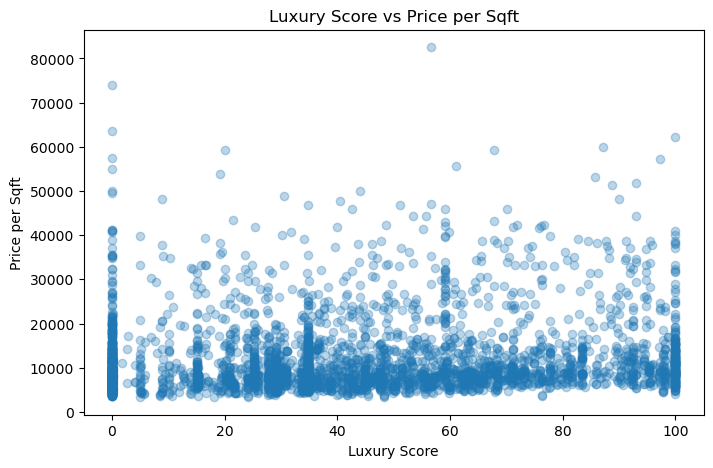

In [37]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.scatter(
    df_model["luxury_score"],
    df_model["price_per_sqft"],
    alpha=0.3
)

plt.xlabel("Luxury Score")
plt.ylabel("Price per Sqft")
plt.title("Luxury Score vs Price per Sqft")

plt.show()

In [38]:
import statsmodels.api as sm

validation_data = pd.DataFrame({
    "log_price_per_sqft": df_model["log_price_per_sqft"],
    "luxury_score": df_model["luxury_score"],
    "log_area": df_model["log_area"],
    "bedRoom": df_model["bedRoom"],
    "bathroom": df_model["bathroom"],
    "floorNum": df_model["floorNum"]
})

validation_data = pd.concat(
    [
        validation_data.reset_index(drop=True),
        categorical.reset_index(drop=True)
    ],
    axis=1
)

validation_data = validation_data.dropna()

X_validation = validation_data.drop(
    columns=["log_price_per_sqft"]
)

X_validation = sm.add_constant(X_validation)

y_validation = validation_data[
    "log_price_per_sqft"
]

validation_model = sm.OLS(
    y_validation,
    X_validation
).fit()

print(
    validation_model.summary()
)

                            OLS Regression Results                            
Dep. Variable:     log_price_per_sqft   R-squared:                       0.733
Model:                            OLS   Adj. R-squared:                  0.720
Method:                 Least Squares   F-statistic:                     57.61
Date:                Fri, 09 Oct 2026   Prob (F-statistic):               0.00
Time:                        20:44:35   Log-Likelihood:                -467.89
No. Observations:                3657   AIC:                             1270.
Df Residuals:                    3490   BIC:                             2306.
Df Model:                         166                                         
Covariance Type:            nonrobust                                         
                                        coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------------------------
const 

In [39]:
from sklearn.model_selection import GroupKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_squared_error, r2_score

# Base model: property characteristics and location
X_base = pd.concat(
    [controls, categorical],
    axis=1
).astype(float)

# Full model: base variables plus all amenities
X_full = pd.concat(
    [controls, categorical, A],
    axis=1
).astype(float)

y = df_model["log_price_per_sqft"].values
groups = df_model["sector"].values

cv = GroupKFold(n_splits=5)

pred_base = np.zeros(len(df_model))
pred_luxury = np.zeros(len(df_model))

for train_idx, test_idx in cv.split(X_full, y, groups):

    # Split the data
    X_train = X_full.iloc[train_idx]
    X_test = X_full.iloc[test_idx]

    y_train = y[train_idx]

    # Train amenity model using training data only
    amenity_model = Pipeline([
        ("scaler", StandardScaler()),
        ("ridge", Ridge(alpha=100))
    ])

    amenity_model.fit(X_train, y_train)

    # Recover coefficients in original feature units
    coefs = (
        amenity_model.named_steps["ridge"].coef_
        / amenity_model.named_steps["scaler"].scale_
    )

    coef_series = pd.Series(
        coefs,
        index=X_full.columns
    )

    amenity_coefs = coef_series[A.columns]

    # Convert positive coefficients into weights
    positive = amenity_coefs.clip(lower=0)

    if positive.max() > 0:
        fold_weights = 10 * positive / positive.max()
    else:
        fold_weights = positive

    # Calculate scores using training-fold weights only
    train_raw = (
        A.iloc[train_idx]
        .multiply(fold_weights, axis=1)
        .sum(axis=1)
    )

    test_raw = (
        A.iloc[test_idx]
        .multiply(fold_weights, axis=1)
        .sum(axis=1)
    )

    # Normalize using the training-fold maximum
    denominator = max(train_raw.max(), 1e-12)

    train_score = train_raw / denominator * 100
    test_score = test_raw / denominator * 100

    # Model A: controls only
    base_model = Pipeline([
        ("scaler", StandardScaler()),
        ("ridge", Ridge(alpha=100))
    ])

    base_model.fit(
        X_base.iloc[train_idx],
        y_train
    )

    pred_base[test_idx] = base_model.predict(
        X_base.iloc[test_idx]
    )

    # Model B: controls plus learned luxury score
    X_train_luxury = X_base.iloc[train_idx].copy()
    X_test_luxury = X_base.iloc[test_idx].copy()

    X_train_luxury["luxury_score"] = train_score.values
    X_test_luxury["luxury_score"] = test_score.values

    luxury_model = Pipeline([
        ("scaler", StandardScaler()),
        ("ridge", Ridge(alpha=100))
    ])

    luxury_model.fit(X_train_luxury, y_train)

    pred_luxury[test_idx] = luxury_model.predict(
        X_test_luxury
    )

# Compare predictions for properties not used to fit each fold
rmse_base = np.sqrt(mean_squared_error(y, pred_base))
rmse_luxury = np.sqrt(mean_squared_error(y, pred_luxury))

r2_base = r2_score(y, pred_base)
r2_luxury = r2_score(y, pred_luxury)

print("MODEL A: WITHOUT LUXURY SCORE")
print("RMSE:", round(rmse_base, 4))
print("R-squared:", round(r2_base, 4))

print("\nMODEL B: WITH LUXURY SCORE")
print("RMSE:", round(rmse_luxury, 4))
print("R-squared:", round(r2_luxury, 4))

print("\nIMPROVEMENT")
print(
    "RMSE reduction (%):",
    round((rmse_base - rmse_luxury) / rmse_base * 100, 2)
)
print(
    "R-squared improvement:",
    round(r2_luxury - r2_base, 4)
)

MODEL A: WITHOUT LUXURY SCORE
RMSE: 0.4423
R-squared: 0.3082

MODEL B: WITH LUXURY SCORE
RMSE: 0.4401
R-squared: 0.3154

IMPROVEMENT
RMSE reduction (%): 0.52
R-squared improvement: 0.0071


In [40]:
from sklearn.metrics import mean_squared_error, r2_score
import numpy as np
import pandas as pd

fold_results = []

for fold, (train_idx, test_idx) in enumerate(
    cv.split(X_full, y, groups), start=1
):
    y_test = y[test_idx]

    pred_a = pred_base[test_idx]
    pred_b = pred_luxury[test_idx]

    rmse_a = np.sqrt(
        mean_squared_error(y_test, pred_a)
    )

    rmse_b = np.sqrt(
        mean_squared_error(y_test, pred_b)
    )

    r2_a = r2_score(y_test, pred_a)
    r2_b = r2_score(y_test, pred_b)

    fold_results.append({
        "Fold": fold,
        "RMSE without score": rmse_a,
        "RMSE with score": rmse_b,
        "RMSE reduction (%)": (
            (rmse_a - rmse_b) / rmse_a * 100
        ),
        "R2 without score": r2_a,
        "R2 with score": r2_b
    })

fold_results = pd.DataFrame(fold_results)

print(fold_results.round(4).to_string(index=False))
print("\nMean RMSE reduction (%):",
      round(fold_results["RMSE reduction (%)"].mean(), 2))

 Fold  RMSE without score  RMSE with score  RMSE reduction (%)  R2 without score  R2 with score
    1              0.4428           0.4399              0.6631            0.3530         0.3616
    2              0.3948           0.3931              0.4129            0.1813         0.1880
    3              0.5290           0.5261              0.5420            0.2957         0.3033
    4              0.4497           0.4472              0.5683            0.3492         0.3566
    5              0.3797           0.3785              0.3120            0.0116         0.0178

Mean RMSE reduction (%): 0.5


In [41]:
fold_weights_list = []

for fold, (train_idx, test_idx) in enumerate(
    cv.split(X_full, y, groups), start=1
):

    X_train = X_full.iloc[train_idx]
    y_train = y[train_idx]

    model = Pipeline([
        ("scaler", StandardScaler()),
        ("ridge", Ridge(alpha=100))
    ])

    model.fit(X_train, y_train)

    coefficients = (
        model.named_steps["ridge"].coef_
        / model.named_steps["scaler"].scale_
    )

    coef_series = pd.Series(
        coefficients,
        index=X_full.columns
    )

    amenity_coefs = coef_series[amenities]

    positive = amenity_coefs.clip(lower=0)

    if positive.max() > 0:
        weights_fold = 10 * positive / positive.max()
    else:
        weights_fold = positive

    weights_fold = weights_fold.reindex(
        amenities,
        fill_value=0
    )

    fold_weights_list.append(weights_fold)

    print(f"Fold {fold}: {len(train_idx)} training properties")

Fold 1: 2924 training properties
Fold 2: 2926 training properties
Fold 3: 2925 training properties
Fold 4: 2927 training properties
Fold 5: 2926 training properties


In [42]:
fold_weights_df = pd.DataFrame(
    fold_weights_list,
    index=[f"Fold {i}" for i in range(1, 6)]
)

print("Top 20 amenities in each fold:")

for fold in fold_weights_df.index:

    print(f"\n{fold}")

    print(
        fold_weights_df.loc[fold]
        .sort_values(ascending=False)
        .head(20)
    )

Top 20 amenities in each fold:

Fold 1
Park                               10.000000
Swimming Pool                       7.621627
Airy Rooms                          4.265565
Visitor Parking                     3.933655
Low Density Society                 3.650543
Private Garden / Terrace            3.331479
Rain Water Harvesting               2.965538
Club house / Community Center       2.075093
High Ceiling Height                 1.996826
Recently Renovated                  1.833087
Centrally Air Conditioned           1.552506
False Ceiling Lighting              1.518588
Feng Shui / Vaastu Compliant        1.486073
Intercom Facility                   1.301081
Separate entry for servant room     0.565052
Waste Disposal                      0.416107
Spacious Interiors                  0.169890
No open drainage around             0.027759
Shopping Centre                     0.013614
Natural Light                       0.000000
Name: Fold 1, dtype: float64

Fold 2
Park                    

In [43]:
stability = pd.DataFrame({
    "Mean weight": fold_weights_df.mean(axis=0),
    "Std weight": fold_weights_df.std(axis=0),
    "Positive folds": (fold_weights_df > 0).sum(axis=0)
})

stability["Positive frequency (%)"] = (
    stability["Positive folds"] / len(fold_weights_df) * 100
)

stability = stability.sort_values(
    "Mean weight",
    ascending=False
)

print(stability.head(25).round(2))

                                 Mean weight  Std weight  Positive folds  \
Park                                   10.00        0.00               5   
Swimming Pool                           7.08        3.08               5   
Low Density Society                     5.37        2.74               5   
Visitor Parking                         5.29        2.24               5   
Private Garden / Terrace                4.71        2.07               5   
Airy Rooms                              3.68        2.56               4   
Club house / Community Center           3.44        1.38               5   
Centrally Air Conditioned               1.91        2.59               3   
High Ceiling Height                     1.90        2.05               4   
Water Storage                           1.60        1.20               4   
Recently Renovated                      1.46        1.09               4   
Feng Shui / Vaastu Compliant            1.41        1.26               4   
Water soften

In [44]:
stable_amenities = stability[
    (stability["Positive frequency (%)"] >= 80)
    &
    (stability["Mean weight"] > 0)
].sort_values(
    "Mean weight",
    ascending=False
)

print("Amenities with positive weights in at least 4 of 5 folds:")
print(stable_amenities.round(2))

Amenities with positive weights in at least 4 of 5 folds:
                               Mean weight  Std weight  Positive folds  \
Park                                 10.00        0.00               5   
Swimming Pool                         7.08        3.08               5   
Low Density Society                   5.37        2.74               5   
Visitor Parking                       5.29        2.24               5   
Private Garden / Terrace              4.71        2.07               5   
Airy Rooms                            3.68        2.56               4   
Club house / Community Center         3.44        1.38               5   
High Ceiling Height                   1.90        2.05               4   
Water Storage                         1.60        1.20               4   
Recently Renovated                    1.46        1.09               4   
Feng Shui / Vaastu Compliant          1.41        1.26               4   
False Ceiling Lighting                1.36        1.16

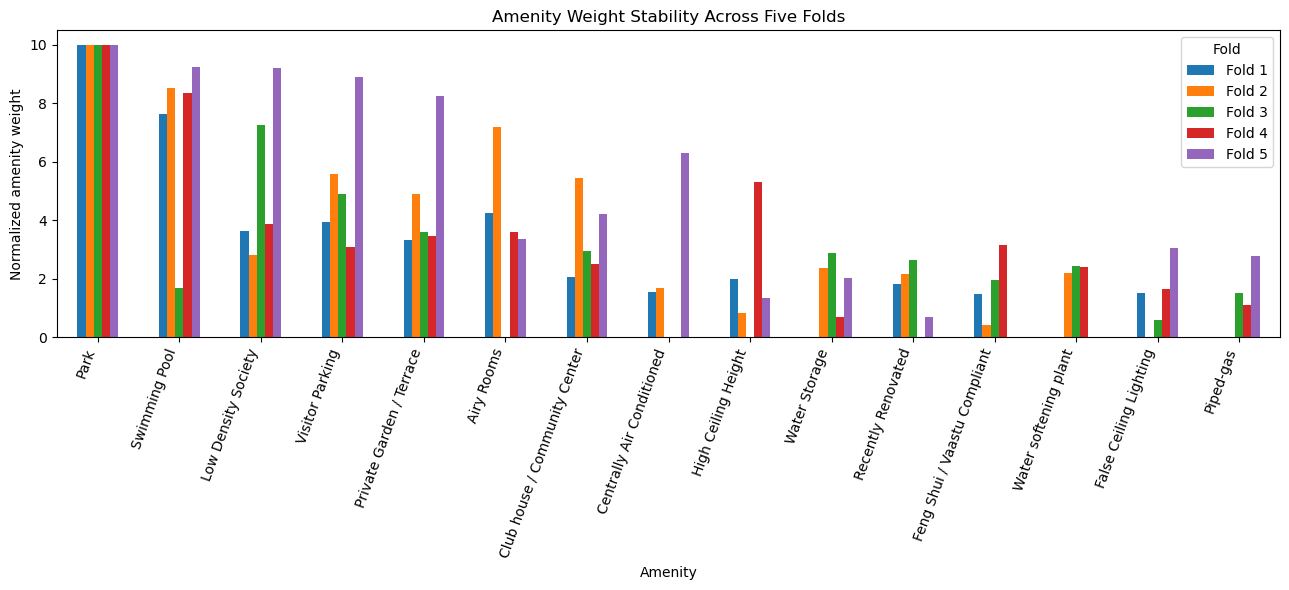

In [45]:
import matplotlib.pyplot as plt

top_amenities = stability.head(15).index

fold_weights_df[top_amenities].T.plot(
    kind="bar",
    figsize=(13, 6)
)

plt.ylabel("Normalized amenity weight")
plt.xlabel("Amenity")
plt.title("Amenity Weight Stability Across Five Folds")
plt.xticks(rotation=70, ha="right")
plt.legend(title="Fold")
plt.tight_layout()
plt.show()

In [46]:
raw_fold_coefficients = []

for fold, (train_idx, test_idx) in enumerate(
    cv.split(X_full, y, groups), start=1
):

    model = Pipeline([
        ("scaler", StandardScaler()),
        ("ridge", Ridge(alpha=100))
    ])

    model.fit(
        X_full.iloc[train_idx],
        y[train_idx]
    )

    coef = (
        model.named_steps["ridge"].coef_
        / model.named_steps["scaler"].scale_
    )

    coef_series = pd.Series(
        coef,
        index=X_full.columns
    )

    raw_fold_coefficients.append(
        coef_series[amenities]
    )

raw_coef_df = pd.DataFrame(
    raw_fold_coefficients,
    index=[f"Fold {i}" for i in range(1, 6)]
)

raw_stability = pd.DataFrame({
    "Mean raw coefficient": raw_coef_df.mean(),
    "SD raw coefficient": raw_coef_df.std(),
    "Positive folds": (raw_coef_df > 0).sum()
})

raw_stability["Positive frequency (%)"] = (
    raw_stability["Positive folds"] / 5 * 100
)

raw_stability = raw_stability.sort_values(
    "Mean raw coefficient",
    ascending=False
)

print(raw_stability.head(25).round(5))

                                 Mean raw coefficient  SD raw coefficient  \
Park                                          0.06618             0.01577   
Swimming Pool                                 0.04386             0.01787   
Low Density Society                           0.03476             0.01772   
Visitor Parking                               0.03318             0.00920   
Private Garden / Terrace                      0.02907             0.00618   
Club house / Community Center                 0.02166             0.00661   
Airy Rooms                                    0.01793             0.02553   
High Ceiling Height                           0.01193             0.01317   
Feng Shui / Vaastu Compliant                  0.00968             0.00928   
Recently Renovated                            0.00895             0.01163   
Water Storage                                 0.00884             0.01178   
Water softening plant                         0.00746             0.01227   

In [47]:
# Select amenities with positive coefficients
# in at least 4 of the 5 folds

stable_amenities = raw_stability[
    raw_stability["Positive folds"] >= 4
].index

# Use the mean raw coefficient for selected amenities
stable_coefficients = (
    raw_coef_df[stable_amenities]
    .mean()
    .clip(lower=0)
)

# Convert coefficients into 0–10 weights
stable_weights = (
    10 * stable_coefficients / stable_coefficients.max()
).round(2)

# Create weights for all amenities
final_stable_weights = pd.Series(
    0.0,
    index=amenities
)

final_stable_weights.loc[
    stable_weights.index
] = stable_weights

print("Stability-filtered weights:")
print(
    final_stable_weights
    .sort_values(ascending=False)
)

Stability-filtered weights:
Park                               10.00
Swimming Pool                       6.63
Low Density Society                 5.25
Visitor Parking                     5.01
Private Garden / Terrace            4.39
Club house / Community Center       3.27
Airy Rooms                          2.71
High Ceiling Height                 1.80
Feng Shui / Vaastu Compliant        1.46
Recently Renovated                  1.35
Water Storage                       1.34
False Ceiling Lighting              1.05
Waste Disposal                      0.64
Centrally Air Conditioned           0.00
Fitness Centre / GYM                0.00
Bank Attached Property              0.00
No open drainage around             0.00
Natural Light                       0.00
Maintenance Staff                   0.00
Lift(s)                             0.00
Intercom Facility                   0.00
Internet/wi-fi connectivity         0.00
Power Back-up                       0.00
Piped-gas                    

In [48]:
stable_raw_score = (
    A[final_stable_weights.index]
    .multiply(final_stable_weights)
    .sum(axis=1)
)

if stable_raw_score.max() > 0:
    stable_score_100 = (
        stable_raw_score / stable_raw_score.max()
    ) * 100
else:
    stable_score_100 = stable_raw_score

df_model["luxury_score_stable"] = (
    stable_score_100.round(2)
)

print(
    df_model[
        ["luxury_score_stable", "price_per_sqft"]
    ].head()
)

   luxury_score_stable  price_per_sqft
0                22.27          7585.0
1                44.32          8600.0
3                39.67          5470.0
4               100.00          8020.0
5                87.88          9022.0


In [49]:
from scipy.stats import spearmanr

# Compare scores on the same properties
comparison = pd.DataFrame({
    "price_per_sqft": df_model["price_per_sqft"],
    "original_score": df_model["luxury_score"],
    "stable_score": df_model["luxury_score_stable"]
}).dropna()

original_corr, original_p = spearmanr(
    comparison["original_score"],
    comparison["price_per_sqft"]
)

stable_corr, stable_p = spearmanr(
    comparison["stable_score"],
    comparison["price_per_sqft"]
)

print("ORIGINAL SCORE")
print("Spearman correlation:", round(original_corr, 4))
print("P-value:", original_p)

print("\nSTABILITY-FILTERED SCORE")
print("Spearman correlation:", round(stable_corr, 4))
print("P-value:", stable_p)

print("\nMEDIAN PRICE PER SQFT BY STABLE SCORE GROUP")

comparison["score_group"] = pd.cut(
    comparison["stable_score"],
    bins=[-0.01, 20, 40, 60, 80, 100.01],
    labels=["Basic", "Standard", "Premium", "Luxury", "Ultra Luxury"]
)

print(
    comparison.groupby(
        "score_group",
        observed=False
    )["price_per_sqft"].agg(
        ["count", "median", "mean"]
    )
)


ORIGINAL SCORE
Spearman correlation: 0.1614
P-value: 8.996528199067866e-23

STABILITY-FILTERED SCORE
Spearman correlation: 0.1074
P-value: 7.477791883298272e-11

MEDIAN PRICE PER SQFT BY STABLE SCORE GROUP
              count   median          mean
score_group                               
Basic           763   8784.0  11676.440367
Standard        823   8376.0  10867.896719
Premium         670   9161.0  12674.350746
Luxury          669   8554.0  11268.901345
Ultra Luxury    732  10053.0  12436.898907
